In [1]:
# Cell 1: Imports and Setup

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pyedflib
import os
import random
import warnings
warnings.filterwarnings('ignore')

data_dir = '../data/'
sfreq    = 256

print("✓ Imports loaded")
print(f"  data_dir: {data_dir}")
print(f"  chb01 exists: {os.path.exists(os.path.join(data_dir, 'chb01'))}")

✓ Imports loaded
  data_dir: ../data/
  chb01 exists: True


In [3]:
# Cell 2: Parse all patient summary files

def parse_summary_file(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    if not os.path.exists(summary_path):
        return []
    with open(summary_path, 'r') as f:
        content = f.read()
    seizures = []
    current_file = None
    lines = content.split('\n')
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if 'File Name:' in line:
            current_file = line.split('File Name:')[-1].strip()
        if current_file and ('Seizure' in line) and ('Start Time' in line):
            try:
                start_part = line.split('Start Time:')[-1].strip()
                start = int(''.join(filter(str.isdigit, start_part.split('seconds')[0])))
                for j in range(i+1, min(i+5, len(lines))):
                    next_line = lines[j].strip()
                    if 'End Time' in next_line:
                        end_part = next_line.split('End Time:')[-1].strip()
                        end = int(''.join(filter(str.isdigit, end_part.split('seconds')[0])))
                        seizures.append({
                            'file':    current_file,
                            'start':   start,
                            'end':     end,
                            'patient': patient_id
                        })
                        break
            except:
                pass
        i += 1
    return seizures

patient_ids = [f'chb{str(i).zfill(2)}' for i in range(1, 25) if i != 21]
all_patients_seizures = {}
for patient_id in patient_ids:
    seizures = parse_summary_file(patient_id)
    if len(seizures) > 0:
        all_patients_seizures[patient_id] = seizures

print(f"✓ {len(all_patients_seizures)} patients parsed")
print(f"✓ {sum(len(v) for v in all_patients_seizures.values())} total seizures")

✓ 23 patients parsed
✓ 194 total seizures


In [4]:
# Cell 3: Feature extraction and helper functions

def get_patient_channels(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    valid_channels = []
    found_channels = False
    with open(summary_path, 'r', errors='ignore') as f:
        lines = f.readlines()
    for line in lines:
        line = line.strip()
        if 'Channels in EDF' in line:
            found_channels = True
            continue
        if found_channels and line.startswith('File Name:'):
            break
        if found_channels and line.startswith('Channel ') and ':' in line:
            parts = line.split(':')
            if len(parts) >= 2:
                try:
                    ch_name = parts[1].strip()
                    ch_idx  = int(parts[0].replace('Channel', '').strip()) - 1
                    if ch_name != '-' and ch_name != '':
                        valid_channels.append((ch_idx, ch_name))
                except ValueError:
                    continue
    return valid_channels

def extract_eeg(patient_id, filename, channel_idx):
    filepath = os.path.join(data_dir, patient_id, filename)
    f = pyedflib.EdfReader(filepath)
    if channel_idx >= f.signals_in_file:
        f.close()
        return None
    sig = f.readSignal(channel_idx)
    f.close()
    return sig

def calculate_entropy(seg):
    hist, _ = np.histogram(seg, bins=50)
    hist = hist / np.sum(hist)
    hist = hist[hist > 0]
    return -np.sum(hist * np.log2(hist))

def calculate_line_length(seg):
    return np.sum(np.abs(np.diff(seg)))

def calculate_high_freq_power(seg, sfreq=256):
    nperseg = min(1024, len(seg))
    f, pxx  = signal.welch(seg, sfreq, nperseg=nperseg)
    return np.sum(pxx[f >= 20])

def get_prev_file(patient_id, current_file):
    patient_dir = os.path.join(data_dir, patient_id)
    all_files   = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    if current_file not in all_files:
        return None
    idx = all_files.index(current_file)
    return all_files[idx-1] if idx > 0 else None

def get_next_file(patient_id, current_file):
    patient_dir = os.path.join(data_dir, patient_id)
    all_files   = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    if current_file not in all_files:
        return None
    idx = all_files.index(current_file)
    return all_files[idx+1] if idx < len(all_files) - 1 else None

def get_file_duration(patient_id, filename):
    filepath = os.path.join(data_dir, patient_id, filename)
    f = pyedflib.EdfReader(filepath)
    dur = f.getNSamples()[0] / sfreq
    f.close()
    return dur

print("✓ All functions defined")

✓ All functions defined


In [5]:
# Cell 4: Compute temporal trends for 5 patients
# chb01, chb03, chb06, chb08, chb20
# for each patient compute mean trend across all valid seizures

TREND_DURATION   = 3600  # 60 min before seizure
POSTICTAL_SEC    = 1800  # 30 min after seizure
TREND_WINDOW_SEC = 120   # 2-min windows
TREND_STEP_SEC   = 60    # slide every 1 min
MIN_POSTICTAL    = 25    # minimum postictal minutes required

selected_patients = ['chb01', 'chb03', 'chb06', 'chb08', 'chb20']

patient_means = {}

for patient_id in selected_patients:
    print(f"\nProcessing {patient_id}...")
    
    seizures     = all_patients_seizures[patient_id]
    channel_info = get_patient_channels(patient_id)
    patient_dir  = os.path.join(data_dir, patient_id)
    
    sz_trends = {}
    
    for sz_idx, sz in enumerate(seizures):
        sz_start    = sz['start']
        sz_end      = sz['end']
        sz_file     = sz['file']
        sz_duration = sz_end - sz_start
        prev_file   = get_prev_file(patient_id, sz_file)
        next_file   = get_next_file(patient_id, sz_file)
        
        need_from_prev = TREND_DURATION - sz_start
        
        try:
            file_dur = get_file_duration(patient_id, sz_file)
        except:
            continue
        
        postictal_available = file_dur - sz_end
        need_from_next      = max(0, POSTICTAL_SEC - postictal_available)
        
        # load and stitch channels
        stitched_channels = []
        for ch_idx, ch_name in channel_info:
            try:
                eeg_current = extract_eeg(patient_id, sz_file, ch_idx)
                if eeg_current is None:
                    stitched_channels.append(None)
                    continue
                
                # stitch previous file for preictal
                if need_from_prev > 0 and prev_file is not None:
                    eeg_prev = extract_eeg(patient_id, prev_file, ch_idx)
                    if eeg_prev is not None:
                        prev_samples = int(need_from_prev * sfreq)
                        eeg_combined = np.concatenate([eeg_prev[-prev_samples:], eeg_current])
                    else:
                        eeg_combined = eeg_current
                else:
                    eeg_combined = eeg_current
                
                # stitch next file for postictal
                if need_from_next > 0 and next_file is not None:
                    eeg_next = extract_eeg(patient_id, next_file, ch_idx)
                    if eeg_next is not None:
                        next_samples = int(need_from_next * sfreq)
                        eeg_combined = np.concatenate([eeg_combined, eeg_next[:next_samples]])
                
                stitched_channels.append(eeg_combined)
                
            except:
                stitched_channels.append(None)
        
        # extract features
        seizure_onset_in_signal = TREND_DURATION
        valid_channels = [c for c in stitched_channels if c is not None]
        if len(valid_channels) == 0:
            continue
        
        total_samples  = len(valid_channels[0])
        window_samples = int(TREND_WINDOW_SEC * sfreq)
        step_samples   = int(TREND_STEP_SEC   * sfreq)
        
        times_min   = []
        avg_entropy = []
        avg_ll      = []
        avg_hf      = []
        
        current_sample = 0
        while current_sample + window_samples <= total_samples:
            w_entropy = []
            w_ll      = []
            w_hf      = []
            
            for ch_sig in stitched_channels:
                if ch_sig is None:
                    continue
                seg = ch_sig[current_sample:current_sample + window_samples]
                if len(seg) > 0:
                    w_entropy.append(calculate_entropy(seg))
                    w_ll.append(calculate_line_length(seg))
                    w_hf.append(calculate_high_freq_power(seg, sfreq))
            
            time_min = (current_sample - seizure_onset_in_signal * sfreq) / sfreq / 60
            times_min.append(time_min)
            avg_entropy.append(np.mean(w_entropy))
            avg_ll.append(np.mean(w_ll))
            avg_hf.append(np.mean(w_hf))
            
            current_sample += step_samples
        
        sz_trends[sz_idx] = {
            'times':   times_min,
            'entropy': avg_entropy,
            'll':      avg_ll,
            'hf':      avg_hf,
        }
    
    # only use seizures with enough postictal data
    valid_sz = [i for i in sz_trends if max(sz_trends[i]['times']) >= MIN_POSTICTAL]
    print(f"  ✓ {len(sz_trends)} seizures processed, {len(valid_sz)} with full postictal")
    
    if len(valid_sz) == 0:
        print(f"  ✗ No valid seizures for {patient_id} — skipping")
        continue
    
    # find common time range
    min_t = max([min(sz_trends[i]['times']) for i in valid_sz])
    max_t = min([max(sz_trends[i]['times']) for i in valid_sz])
    ref_t = np.arange(min_t, max_t, TREND_STEP_SEC/60)
    
    print(f"  ✓ Common time range: {min_t:.1f} to {max_t:.1f} minutes")
    
    # compute mean across valid seizures
    for fkey in ['entropy', 'll', 'hf']:
        all_vals = []
        for i in valid_sz:
            vals_interp = np.interp(ref_t, sz_trends[i]['times'], sz_trends[i][fkey])
            all_vals.append(vals_interp)
        all_vals = np.array(all_vals)
        patient_means[patient_id] = patient_means.get(patient_id, {})
        patient_means[patient_id][fkey]           = np.mean(all_vals, axis=0)
        patient_means[patient_id]['std_' + fkey]  = np.std(all_vals,  axis=0)
        patient_means[patient_id]['times']         = ref_t
        patient_means[patient_id]['n_seizures']    = len(valid_sz)

print(f"\n✓ All patients processed")
print(f"  Patients with valid data: {list(patient_means.keys())}")


Processing chb01...
  ✓ 7 seizures processed, 6 with full postictal
  ✓ Common time range: -60.0 to 28.0 minutes

Processing chb03...
  ✓ 7 seizures processed, 6 with full postictal
  ✓ Common time range: -60.0 to 28.0 minutes

Processing chb06...
  ✓ 10 seizures processed, 10 with full postictal
  ✓ Common time range: -60.0 to 98.0 minutes

Processing chb08...
  ✓ 5 seizures processed, 4 with full postictal
  ✓ Common time range: -60.0 to 30.0 minutes

Processing chb20...
  ✓ 8 seizures processed, 7 with full postictal
  ✓ Common time range: -60.0 to 28.0 minutes

✓ All patients processed
  Patients with valid data: ['chb01', 'chb03', 'chb06', 'chb08', 'chb20']


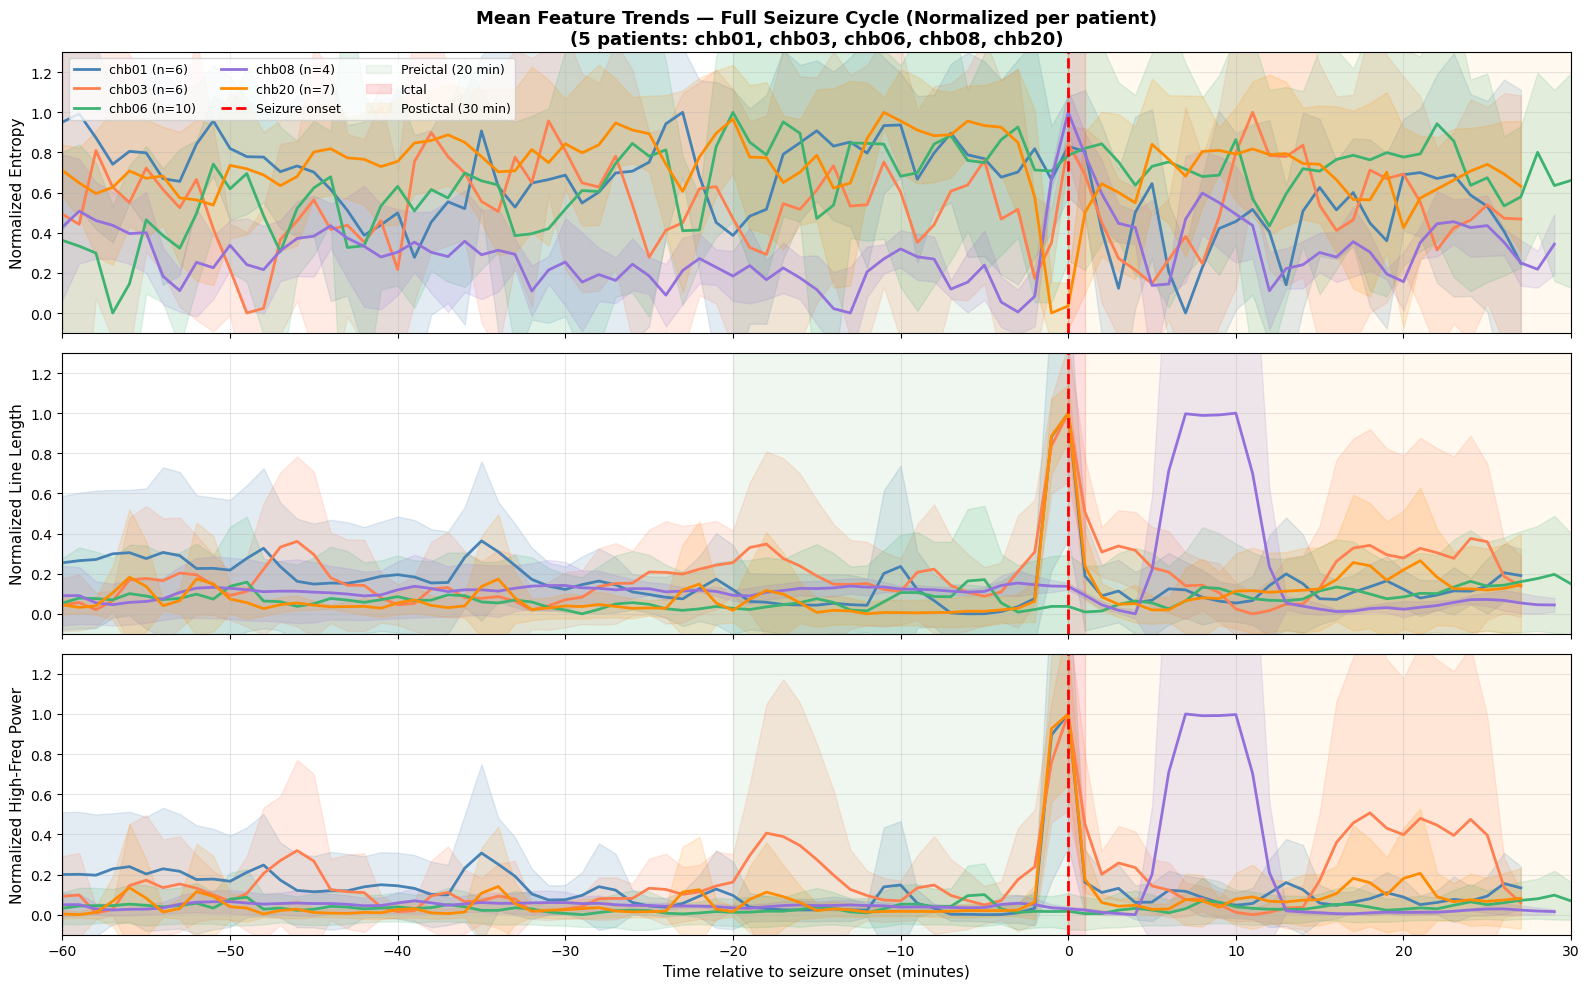

In [7]:
# fix 1: limit x-axis to -60 to +30 minutes
# fix 2: normalize each patient's features to 0-1 scale
# so different patients are comparable on same plot

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

feature_keys   = ['entropy', 'll', 'hf']
feature_labels = ['Normalized Entropy', 'Normalized Line Length', 'Normalized High-Freq Power']

patient_colors = {
    'chb01': 'steelblue',
    'chb03': 'coral',
    'chb06': 'mediumseagreen',
    'chb08': 'mediumpurple',
    'chb20': 'darkorange',
}

for ax, fkey, flabel in zip(axes, feature_keys, feature_labels):
    for patient_id in selected_patients:
        if patient_id not in patient_means:
            continue
        
        ref_t     = patient_means[patient_id]['times']
        mean_vals = patient_means[patient_id][fkey]
        std_vals  = patient_means[patient_id]['std_' + fkey]
        n_sz      = patient_means[patient_id]['n_seizures']
        color     = patient_colors[patient_id]
        
        # normalize to 0-1 scale per patient
        # so all patients are on same scale regardless of absolute values
        min_val = np.min(mean_vals)
        max_val = np.max(mean_vals)
        if max_val - min_val > 0:
            mean_norm = (mean_vals - min_val) / (max_val - min_val)
            std_norm  = std_vals / (max_val - min_val)
        else:
            mean_norm = mean_vals
            std_norm  = std_vals
        
        # only plot -60 to +30 minutes
        mask = (ref_t >= -60) & (ref_t <= 30)
        
        ax.plot(ref_t[mask], mean_norm[mask], color=color,
                linewidth=2, label=f'{patient_id} (n={n_sz})')
        ax.fill_between(ref_t[mask],
                        (mean_norm - std_norm)[mask],
                        (mean_norm + std_norm)[mask],
                        color=color, alpha=0.15)
    
    ax.axvline(0, color='red', linewidth=2,
               linestyle='--', label='Seizure onset')
    ax.axvspan(-20, 0,  alpha=0.06, color='green',  label='Preictal (20 min)')
    ax.axvspan(0,   1,  alpha=0.12, color='red',    label='Ictal')
    ax.axvspan(1,   30, alpha=0.06, color='orange',  label='Postictal (30 min)')
    ax.set_ylabel(flabel, fontsize=11)
    ax.set_ylim(-0.1, 1.3)
    ax.grid(True, alpha=0.3)

axes[0].set_title(
    'Mean Feature Trends — Full Seizure Cycle (Normalized per patient)\n'
    '(5 patients: chb01, chb03, chb06, chb08, chb20)',
    fontsize=13, fontweight='bold'
)
axes[0].legend(loc='upper left', fontsize=9, ncol=3)
axes[2].set_xlabel('Time relative to seizure onset (minutes)', fontsize=11)
axes[2].set_xlim(-60, 30)

plt.tight_layout()
plt.savefig('temporal_trend_5patients_normalized.png', dpi=300, bbox_inches='tight')
plt.show()